# 14장 · 분류 함수와 조건부 라우팅

라우팅 함수는 입력의 분류 결과에 따라 다음에 실행할 함수를 선택합니다. 분류가 모호하거나 실패했을 때 갈 경로도 정해야 합니다.

영수증 위치와 인증 오류는 서로 다른 안내가 필요합니다. 먼저 분류 결과 한 단어를 얻고, 그 값을 받아 어느 작성 규칙을 적용할지는 파이썬 코드가 결정합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 분류 레이블과 복합 의도

재현을 위해 단어가 있는지 검사하는 작은 대역을 씁니다. 실제 분류 모델이 질문을 이해하는 과정을 흉내 내는 함수는 아닙니다.


### 명시적 거절과 분류기 오류

<p>route_request는 ClassificationRefusalError를 만나면 classification_refusal을, 그 밖의 예외를 만나면 classification_error를 반환합니다. 두 경우 모두 작성기를 호출하지 않습니다. 셀의 timed_out은 TimeoutError를 일으켜 두 번째 경로를 보여 줍니다.</p>


### 셀 01 · mock_classify()의 단일 의도 판정

키워드 영수증이 있고 오류는 없는 입력입니다.


In [1]:
def mock_classify(question):
    # 설명용 규칙입니다. 모델 판단을 재현하지 않습니다.
    billing = "영수증" in question
    technical = "오류" in question
    if billing == technical:
        return "clarify"
    return "billing" if billing else "technical"

print(mock_classify("영수증이 필요합니다"))

billing


billing이 나옵니다. 두 단어가 모두 있거나 모두 없으면 이 함수는 분류를 확정하지 않고 clarify를 반환합니다.


### 분류 함수와 실행 함수

<p>분류 모델은 입력이 어느 분야인지 문자열을 제안합니다. 그 문자열로 어떤 작업을 수행할지는 Python 코드가 결정합니다. 모델이 billing이라고 썼다는 이유만으로 결제나 환불이 실제 실행된 것은 아닙니다.</p>

<p>이번 예제는 접수 안내 문장만 만듭니다. 외부 계정 조회·환불·데이터 변경은 하지 않습니다. 경로 분류는 사용자 권한이나 작업 승인도 대신하지 않습니다.</p>

<table><caption>순차 흐름과 분기</caption><thead><tr><th scope="col">구분</th><th scope="col">실행 방식</th><th scope="col">확인점</th></tr>
</thead><tbody><tr><td>13장 순차</td><td>요약→분류→작성 고정</td><td>중간 출력 전달</td></tr>
<tr><td>14장 분기</td><td>분류→결제 또는 기술 작성</td><td>선택된 규칙만 실행</td></tr>
<tr><td>추가 질문</td><td>분류 후 고정 질문 반환</td><td>작성 모델 호출 없음</td></tr>
</tbody></table>


### 과제 02 · 복합 의도의 clarify 분기

영수증과 오류가 모두 있는 한 문장을 만들어 분류값을 확인하세요.


In [2]:
# 복합 문의 하나를 mock_classify에 넣으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>print(mock_classify(&quot;영수증 출력 중 오류가 났어요&quot;))</code></pre>
<p>실행 결과</p><pre><code>clarify</code></pre>
<p>두 조건이 모두 참이라 결과는 clarify입니다. 어떤 분야인지 더 물은 뒤에 작성할 수 있습니다.</p>
</details>


### 입력 유형별 라우팅 테스트

<table><caption>기본 모의 결과</caption><thead><tr><th scope="col">질문</th><th scope="col">경로</th><th scope="col">작성 횟수</th></tr>
</thead><tbody><tr><td>영수증이 필요합니다</td><td>billing</td><td>1</td></tr>
<tr><td>인증 오류입니다</td><td>technical</td><td>1</td></tr>
<tr><td>영수증과 오류</td><td>clarify</td><td>0</td></tr>
<tr><td>도와주세요</td><td>clarify</td><td>0</td></tr>
</tbody></table>

<p>기본 모의 분류는 “영수증”과 “오류”가 있는지만 검사하는 Python 규칙입니다. 실제 LLM의 의미 이해를 흉내 낸 결과로 평가하지 않습니다. “결제 내역을 받고 싶어요”처럼 같은 의도를 다른 표현으로 쓰면 이 규칙은 추가 질문으로 보냅니다.</p>


## route_request()의 분기와 실패 처리

허용하는 작성 규칙은 billing과 technical 둘입니다. 규칙을 찾을 수 있으면 한 번 쓰고, 그렇지 않으면 추가 설명을 요청합니다. 아래의 write는 문구 생성 과정을 대신하는 모의 함수입니다.

<!-- lesson-visual practice-space -->
**영수증과 오류가 동시에 나오면 어디로 갈까요?**

수업의 분류 함수는 두 단어의 포함 여부를 검사합니다. 질문을 바꾸면서 강조되는 경로와 안내 작성 함수의 호출 수를 확인하세요.

두 단서 중 하나만 있을 때는 해당 경로에서 1회 작성합니다. 둘 다 있거나 모두 없으면 clarify로 이동하고 작성 횟수는 0입니다.

[웹 교재에서 직접 조작하기](https://langchain-lecture.vercel.app/chapter14/#practice-space)
<!-- /lesson-visual practice-space -->


### 순차 실행에서 조건부 실행으로

<p>13장에서는 정상적인 문의가 요약·분류·작성 단계를 모두 거쳤습니다. 여기서는 먼저 route를 판정한 뒤 작성 호출을 할지 결정합니다. technical이면 해당 작성 규칙을 사용하고 clarify이면 추가 질문을 곧바로 반환합니다.</p>


### 분류기의 시간 초과는 어느 경로로 돌아올까요?

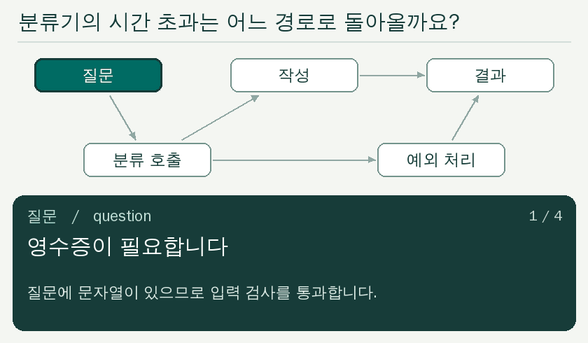

timed_out을 분류 함수로 넣으면 결제 단서가 있는 질문도 작성 함수까지 도달하지 못합니다. 여기서 clarify의 원인은 classification_error입니다.


### 셀 03 · route_request()로 실행 경로 선택

제공 함수의 writes는 최종 안내 작성 함수를 실제로 몇 번 불렀는지 표시합니다.

분류기가 빈 문자열을 그대로 반환하면 작성 규칙을 찾지 못해 needs_clarification으로 끝납니다. SDK 연결부가 먼저 빈 응답을 예외로 처리하면 route_request는 classification_error를 기록합니다. 어느 쪽도 작성 함수를 부르지 않습니다.


In [3]:
WRITING_RULES = {"billing": "결제 문의의 접수 안내를 작성하세요.", "technical": "기술 문의의 확인 항목을 작성하세요."}

class ClassificationRefusalError(ValueError):
    """명시적 거절을 정상적인 추가 질문과 구분하는 예외입니다."""

def route_request(classify, write, question):
    if not question.strip():
        raise ValueError("빈 질문")
    try:
        route = classify(question)
    except ClassificationRefusalError as exc:
        return {"route": "clarify", "reason": "classification_refusal",
                "error_type": type(exc).__name__, "answer": "분류 요청이 거절되었습니다. 요청 내용을 확인하세요.", "writes": 0}
    except Exception as exc:
        return {"route": "clarify", "reason": "classification_error",
                "error_type": type(exc).__name__, "answer": "분류에 실패했습니다. 잠시 뒤 다시 확인하세요.", "writes": 0}
    if route not in WRITING_RULES:
        return {"route": "clarify", "reason": "needs_clarification",
                "answer": "결제 문의인지 기술 문제인지 구체적으로 알려 주세요.", "writes": 0}
    answer = write(WRITING_RULES[route], question)
    return {"route": route, "reason": "classified", "answer": answer, "writes": 1}

def mock_write(instruction, question):
    return "[모의 안내] " + instruction

result = route_request(mock_classify, mock_write, "인증 오류입니다")
print(result["route"], result["writes"])

technical 1


technical 1은 기술 문의 규칙으로 작성 함수를 한 번 실행했다는 뜻입니다. 분류 호출은 writes에 들어가지 않습니다.


### 허용 경로 검증

<p>WRITING_RULES의 키가 허용 목록입니다. 분류 결과가 딕셔너리에 없으면 코드가 추가 질문 경로를 선택합니다. 모델이 반환한 문자열을 eval로 실행하거나 같은 이름의 임의 함수를 찾지 않습니다.</p>

<h3>분류 뒤의 실행 결정</h3>

<p>정확한 흐름을 설명하는 시각화이며 실제 모델 호출이 아닙니다.</p>

<table><caption>조건별 다음 단계</caption><thead><tr><th scope="col">분류 결과</th><th scope="col">바로 다음 행동</th></tr>
</thead><tbody><tr><td>clarify</td><td>추가 질문을 반환하고 종료 · 작성 호출 0회</td></tr>
<tr><td>등록된 작성 경로</td><td>해당 규칙을 꺼내 안내문 작성</td></tr>
</tbody></table>

<article><small>STEP 01 · Python</small><h4>분류 전 입력 검사</h4>
<p>빈 질문을 먼저 거부합니다.</p><pre>question</pre></article>

<article><small>STEP 02 · 모델 또는 모의 함수</small><h4>라우팅 후보 반환</h4>
<p>billing / technical / clarify를 제안합니다.</p><pre>route</pre></article>

<article><small>STEP 03 · Python</small><h4>허용 경로 대조</h4>
<p>목록에 없으면 추가 질문을 반환합니다.</p><pre>route in WRITING_RULES</pre></article>

<article><small>STEP 04 · Python → 모델</small><h4>선택한 응답 규칙 실행</h4>
<p>결제 또는 기술 규칙 하나만 사용합니다.</p><pre>작성 경로에서만 answer 생성</pre></article>


### 셀 04 · 분류 시간 초과 처리

분류기가 답을 돌려주기 전에 시간 초과가 났다고 가정합니다.


In [4]:
def timed_out(question):
    raise TimeoutError("분류 대기 시간 초과")

failed = route_request(timed_out, mock_write, "영수증이 필요합니다")
print(failed["reason"], failed["writes"])

classification_error 0


classification_error 0입니다. 문의가 모호했기 때문이 아니라 분류 과정에서 실패해 작성까지 가지 못했습니다.


### 분류 예외와 정상적인 추가 질문

<p>분류 함수가 TimeoutError를 내면 reason은 classification_error입니다. 두 분야의 단서가 함께 있어 분류 함수가 clarify를 돌려주면 needs_clarification입니다. 두 경우 모두 writes는 0이지만 원인 기록이 다릅니다.</p>


## clarify 경로와 추가 질문

복합 문의와 시스템 오류의 화면 문구가 같으면 사용자가 올바른 다음 행동을 고르기 어렵습니다. 한 건의 분류 기록에서 이유와 안내를 함께 읽습니다.


### 경계 입력과 원인별 로그

<p>분류는 쉬운 질문보다 모호·복합·범위 밖 입력에서 설계 차이가 드러납니다. 두 분야를 동시에 묻는 질문에 하나만 골라 답하면 나머지 요청이 사라질 수 있습니다. 이번 수업에서는 복합 입력을 추가 질문으로 돌려 범위를 좁힙니다.</p>

<p>분류 함수가 예상하지 않은 delete_all을 반환하는 테스트는 악의적인 실제 작업을 실행하지 않습니다. 그런 문자열이 와도 허용 목록 밖이면 작성 호출이 없다는 경계를 검사합니다.</p>


### 과제 05 · clarify 분기의 응답값

‘도와주세요’를 route_request에 넣고 기록에서 사용자에게 보여 줄 답변을 꺼내세요.


In [5]:
# 요청을 처리한 뒤 answer를 출력하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>ambiguous = route_request(mock_classify, mock_write, &quot;도와주세요&quot;)
print(ambiguous[&quot;answer&quot;])</code></pre>
<p>실행 결과</p><pre><code>결제 문의인지 기술 문제인지 구체적으로 알려 주세요.</code></pre>
<p>결제 문의인지 기술 문제인지 구체적으로 알려 달라는 안내입니다. 분류 실패의 ‘잠시 뒤 다시 확인’과는 다음 행동이 다릅니다.</p>
</details>


### 분기 정책 비교 실습

<p>다음 장에서는 모델이 함수 이름과 인자를 요청하는 Function Calling을 배웁니다. 오늘의 분류 문자열과 도구 호출 요청은 서로 다른 자료구조입니다.</p>


## 돌아보기

정상 분류, 복합 문의, 분류 시간 초과 중 한 건을 골라 어디서 분기하는지 설명해 보세요. reason으로 분기 이유를, writes로 작성 함수를 몇 번 불렀는지 확인할 수 있습니다.

### 분류 뒤의 실행 결정

**질문 검사**　빈 질문을 먼저 거부합니다.

```
question
```

**후보 경로 반환**　billing / technical / clarify를 제안합니다.

```
route
```

**등록된 규칙 확인**　목록에 없으면 추가 질문을 반환합니다.

```
route in WRITING_RULES
```

**해당 규칙으로 안내**　결제 또는 기술 규칙 하나만 사용합니다.

```
작성 경로에서만 answer 생성
```
